# DIP Assignment 1 — Problem 1: Convolution

**Name:** Kushal Mukherjee &nbsp;&nbsp; **Roll number:** 2025201072

In [1]:
import time
import platform
import subprocess

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

from scipy.signal import convolve2d, correlate2d   # checking only

ROOT = Path.cwd()

print("CPU    :", subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip())
print("Cores  :", subprocess.check_output(["sysctl", "-n", "hw.ncpu"]).decode().strip())
print("RAM    :", round(int(subprocess.check_output(["sysctl", "-n", "hw.memsize"])) / 1e9), "GB")
print("OS     :", platform.platform())
print("Python :", platform.python_version())
print("NumPy  :", np.__version__)

CPU    : Apple M4
Cores  : 10
RAM    : 17 GB
OS     : macOS-15.7.7-arm64-arm-64bit-Mach-O
Python : 3.13.9
NumPy  : 2.4.1


---
# Problem 1 — Convolution

## The kernel bank

This is the bank supplied with the assignment, used unmodified so that my rank table matches
the one the handout expects. For a given `k` it uses $\sigma = k/6$ and measures
$r^2 = x^2 + y^2$ from the centre of the window.

In [2]:
def kernel_bank(k=15):
    """Provided. Do not modify -- your rank table must match these kernels."""
    ax = np.arange(k) - (k - 1) / 2
    box = np.ones((k, k)) / (k * k)
    s = k / 6.0
    g1 = np.exp(-(ax**2) / (2 * s * s))
    g1 /= g1.sum()
    gauss = np.outer(g1, g1)
    sobel = np.outer([1, 2, 1], [-1, 0, 1]).astype(float)
    xx, yy = np.meshgrid(ax, ax)
    r2 = xx**2 + yy**2
    log = (r2 - 2 * s * s) / (s**4) * np.exp(-r2 / (2 * s * s))
    motion0 = np.zeros((k, k))
    motion0[k // 2, :] = 1.0 / k
    disk = (r2 <= (k / 2.0) ** 2).astype(float)
    disk /= disk.sum()
    rand = np.random.default_rng(0).normal(size=(k, k))
    rand /= np.abs(rand).sum()
    return {
        "box": box,
        "gaussian": gauss,
        "sobel3": sobel,
        "log": log,
        "log_dc_removed": log - log.mean(),
        "motion_0deg": motion0,
        "motion_45deg": np.eye(k) / k,
        "disk": disk,
        "random": rand,
    }

## 1.1 — Four implementations of 2-D convolution

All four use `mode='same'`, zero padding, and **true convolution**, meaning the kernel is
flipped by 180° before the sliding sum. The distinction matters: correlation slides the kernel
as-is, so for any kernel that is not symmetric the two give different answers. I check this
explicitly further down.

In [3]:
def conv2d_loops(img, K):
    """Four nested Python loops. Only run this on small crops."""
    H, W = img.shape
    kh, kw = K.shape

    K_flip = np.flip(K)

    pad_h = kh // 2
    pad_w = kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0)

    out = np.zeros((H, W), dtype=np.float64)

    for i in range(H):
        for j in range(W):
            for ki in range(kh):
                for kj in range(kw):
                    out[i, j] += padded[i + ki, j + kj] * K_flip[ki, kj]

    return out

In [4]:
def conv2d_taps(img, K):
    """Loop over the k*k kernel taps, vectorised over the whole image."""
    H, W = img.shape
    kh, kw = K.shape

    K_flip = np.flip(K)

    pad_h = kh // 2
    pad_w = kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0)

    out = np.zeros((H, W), dtype=np.float64)

    for ki in range(kh):
        for kj in range(kw):
            out += K_flip[ki, kj] * padded[ki : ki + H, kj : kj + W]

    return out

In [5]:
def conv2d_im2col(img, K):
    """Build the (H*W, kh*kw) patch matrix, then one matrix-vector product."""
    H, W = img.shape
    kh, kw = K.shape

    K_flip = np.flip(K)

    pad_h = kh // 2
    pad_w = kw // 2
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="constant", constant_values=0)

    windows = np.lib.stride_tricks.sliding_window_view(padded, (kh, kw))
    patches = windows.reshape(H * W, kh * kw)

    kernel_vector = K_flip.reshape(kh * kw)

    out = patches @ kernel_vector

    return out.reshape(H, W)

In [6]:
def conv2d_fft(img, K):
    """Multiply in the frequency domain.

    No flip here: multiplying the two FFTs already IS convolution, so flipping
    the kernel first would give correlation instead.
    """
    H, W = img.shape
    kh, kw = K.shape

    fh = H + kh - 1
    fw = W + kw - 1

    img_pad = np.zeros((fh, fw), dtype=np.float64)
    K_pad = np.zeros((fh, fw), dtype=np.float64)

    img_pad[:H, :W] = img
    K_pad[:kh, :kw] = K

    full = np.fft.ifft2(np.fft.fft2(img_pad) * np.fft.fft2(K_pad)).real

    pad_h = kh // 2
    pad_w = kw // 2

    return full[pad_h : pad_h + H, pad_w : pad_w + W]

In [7]:
def psnr(a, b, peak=255.0):
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(peak * peak / mse)

### Correctness check

I verify all four against `scipy.signal.convolve2d` on a 128×128 crop. I deliberately include
**asymmetric** kernels (`random`, `sobel3`, `motion_0deg`) as well as symmetric ones. A check
that only uses a symmetric kernel cannot detect a missing or spurious kernel flip, because for
symmetric $K$ we have $\mathrm{flip}(K) = K$ and convolution and correlation coincide.

In [8]:
img128 = np.asarray(Image.open(ROOT / "images/p1/base_2048.png")).astype(float)[:128, :128]

print(f"{'kernel':14s} {'loops':>12} {'taps':>12} {'im2col':>12} {'fft':>12}")

for name in ["gaussian", "log", "random", "sobel3", "motion_0deg"]:
    K = kernel_bank(7)[name]
    ref = convolve2d(img128, K, mode="same", boundary="fill")

    errs = [np.abs(fn(img128, K) - ref).max()
            for fn in (conv2d_loops, conv2d_taps, conv2d_im2col, conv2d_fft)]

    print(f"{name:14s} " + " ".join(f"{e:12.2e}" for e in errs))

kernel                loops         taps       im2col          fft


gaussian           1.71e-13     1.71e-13     1.71e-13     2.56e-13


log                3.98e-13     3.98e-13     3.41e-13     4.55e-13


random             5.33e-14     5.33e-14     4.97e-14     4.62e-14
sobel3             0.00e+00     0.00e+00     0.00e+00     5.26e-13


motion_0deg        8.53e-14     8.53e-14     5.68e-14     2.84e-13


All four agree with SciPy to around $10^{-13}$, which is float64 round-off for sums of this
length — they are the same computation, not merely similar ones.

### Convolution is not correlation

With an asymmetric kernel the two operations give visibly different outputs. The kernel below
is deliberately non-symmetric.

max |convolution - correlation| = 2160.0
max |convolution|               = 5078.0


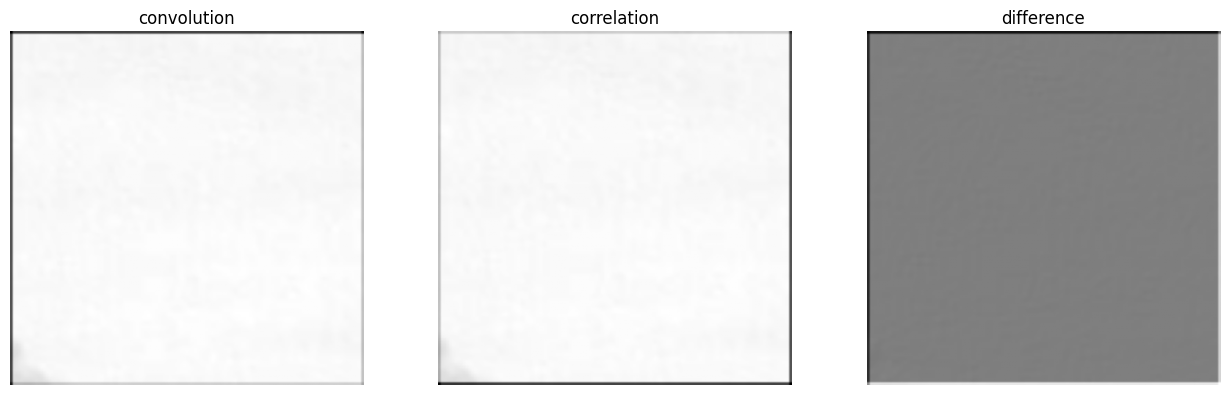

In [9]:
K_asym = np.array([[1, 2, 0],
                   [3, 4, 5],
                   [0, 6, 7]], dtype=float)

conv = conv2d_loops(img128, K_asym)
corr = correlate2d(img128, K_asym, mode="same", boundary="fill")

print("max |convolution - correlation| =", np.abs(conv - corr).max())
print("max |convolution|               =", np.abs(conv).max())

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
ax[0].imshow(conv, cmap="gray");        ax[0].set_title("convolution")
ax[1].imshow(corr, cmap="gray");        ax[1].set_title("correlation")
ax[2].imshow(conv - corr, cmap="gray"); ax[2].set_title("difference")
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.show()

The difference is not a small numerical discrepancy — it is a genuinely different operator.
Flipping the kernel reverses the sense of the asymmetry, so edges that the correlation
response brightens on one side, the convolution response brightens on the other.

### Cost of the naive loop

I time `conv2d_loops` on the 128×128 crop at $k=7$ and extrapolate. The loop body executes
$H \cdot W \cdot k^2$ times, so runtime scales as $N^2 k^2$.

In [10]:
K7 = kernel_bank(7)["gaussian"]

start = time.perf_counter()
conv2d_loops(img128, K7)
elapsed = time.perf_counter() - start

scale = (2048 / 128) ** 2 * (15 / 7) ** 2
predicted = elapsed * scale

print(f"measured  128x128, k=7   : {elapsed:.3f} s")
print(f"scale factor to 2048, k=15: {scale:.1f}x")
print(f"predicted 2048x2048, k=15: {predicted:.1f} s = {predicted / 60:.1f} min")
print(f"per inner iteration       : {elapsed / (128 * 128 * 49) * 1e9:.0f} ns")

measured  128x128, k=7   : 0.158 s
scale factor to 2048, k=15: 1175.5x
predicted 2048x2048, k=15: 185.5 s = 3.1 min
per inner iteration       : 197 ns


**Why I was not asked to run the full-size version.** The prediction is roughly three minutes,
so it is not literally impossible — but it is pointless. The tap loop computes the identical
result on the full 2048×2048 image at $k=15$ in under a second, so the naive version costs
about a thousand times more for nothing. The reason is that each of the ~940 million inner
iterations is an interpreted Python step costing around 200 ns, whereas the vectorised version
pushes the same multiply-accumulates through NumPy at memory-bandwidth speed. The point of the
exercise is that the $N^2k^2$ cost model lets me predict the large case from a cheap small
measurement, so actually paying for it adds no information.

## 1.2 — Kernel rank

I call a singular value zero when it falls below a fixed tolerance:

In [11]:
def numeric_rank(K, tol=1e-10):
    S = np.linalg.svd(K, compute_uv=False)
    return np.sum(S > tol)

In [12]:
kernels = kernel_bank(15)

print(f"{'kernel':16s} {'rank':>5} {'sigma_1':>12} {'last kept':>12} {'first dropped':>14}")

for name, K in kernels.items():
    S = np.linalg.svd(K, compute_uv=False)
    r = numeric_rank(K)
    nxt = S[r] if r < len(S) else 0.0
    print(f"{name:16s} {r:5d} {S[0]:12.4e} {S[r - 1]:12.4e} {nxt:14.4e}")

kernel            rank      sigma_1    last kept  first dropped
box                  1   6.6667e-02   6.6667e-02     1.7196e-18
gaussian             1   1.1341e-01   1.1341e-01     6.9913e-18
sobel3               1   3.4641e+00   3.4641e+00     3.6501e-16
log                  2   9.6797e-01   2.5875e-01     8.3749e-17
log_dc_removed       3   9.6381e-01   2.9751e-03     4.2435e-17
motion_0deg          1   2.5820e-01   2.5820e-01     0.0000e+00
motion_45deg        15   6.6667e-02   6.6667e-02     0.0000e+00
disk                 5   7.1102e-02   6.5339e-03     1.8165e-18
random              15   4.1244e-02   7.7021e-04     0.0000e+00


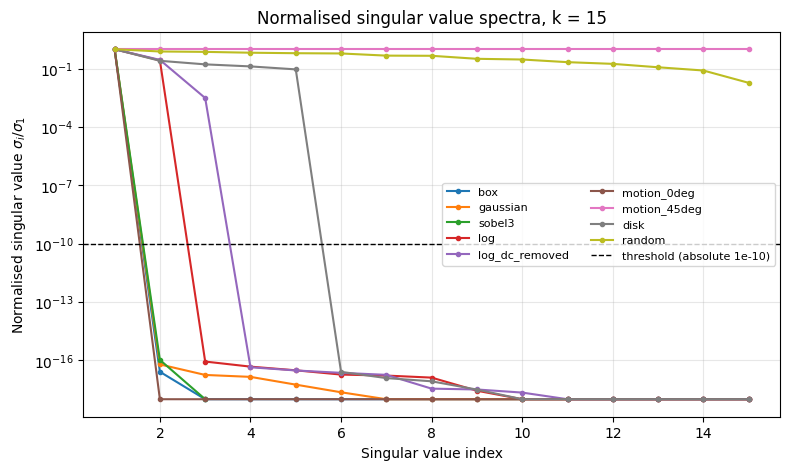

In [13]:
plt.figure(figsize=(9, 5))

for name, K in kernels.items():
    S = np.linalg.svd(K, compute_uv=False)
    plt.semilogy(range(1, len(S) + 1), np.maximum(S / S[0], 1e-18), marker="o", ms=3, label=name)

plt.axhline(1e-10, color="k", ls="--", lw=1, label="threshold (absolute 1e-10)")
plt.xlabel("Singular value index")
plt.ylabel("Normalised singular value $\\sigma_i / \\sigma_1$")
plt.title("Normalised singular value spectra, k = 15")
plt.legend(fontsize=8, ncol=2)
plt.grid(True, alpha=0.3)
plt.show()

**The threshold and why it matters.** I call $\sigma_i$ zero when $\sigma_i < 10^{-10}$.
The table shows this is safe *for this bank*: the smallest singular value I keep is around
$10^{-3}$ and the largest I drop is around $10^{-17}$, so the cut sits in an empty gap
spanning fourteen orders of magnitude, and moving it anywhere inside that gap changes nothing.

The choice matters because rank is a discrete decision made on continuous data. Every kernel
here has *some* tiny non-zero singular values from float64 round-off, so "rank" really means
"how many singular values are above the noise floor." Two consequences:

- An **absolute** threshold like mine is scale-dependent. Multiplying a kernel by $10^{-12}$
  does not change its rank mathematically, but it would drive every singular value below
  $10^{-10}$ and my function would report rank 0. A **relative** test,
  $\sigma_i > \varepsilon\,\sigma_1$, is the scale-invariant version and is what I would use
  if the kernels were not all normalised to $O(1)$ magnitude.
- Where the spectrum decays smoothly rather than falling off a cliff — the `disk` kernel is
  the clear case — the reported rank genuinely depends on where the line is drawn. That is not
  a defect in the measurement; it means "rank" is the wrong question for that kernel and
  *effective* rank, discussed in 1.3, is the useful one.

### (a) Why the raw LoG is exactly rank 2

Write $g(t) = e^{-t^2/2\sigma^2}$, so that
$e^{-r^2/2\sigma^2} = g(x)\,g(y)$. Then

$$\sigma^4 \,\mathrm{LoG}(x,y) = (x^2 + y^2 - 2\sigma^2)\,g(x)g(y).$$

Split the constant symmetrically between the two coordinates:

$$(x^2 + y^2 - 2\sigma^2) = (x^2 - \sigma^2) + (y^2 - \sigma^2),$$

which gives

$$\sigma^4\,\mathrm{LoG}(x,y) = \underbrace{(x^2-\sigma^2)g(x)}_{u(x)}\;g(y)
\;+\; g(x)\;\underbrace{(y^2-\sigma^2)g(y)}_{u(y)}.$$

On the sampled grid this is exactly $\mathbf{u}\mathbf{g}^{\mathsf T} + \mathbf{g}\mathbf{u}^{\mathsf T}$,
a sum of two outer products, so the rank is **at most 2**. It is exactly 2 because $\mathbf{u}$
and $\mathbf{g}$ are linearly independent — $\mathbf{g}$ is strictly positive while
$\mathbf{u}$ changes sign at $|t| = \sigma$, so neither is a multiple of the other. The table
confirms rank 2.

### (b) Why removing the mean raises the rank to exactly 3

`log_dc_removed` is $\mathrm{LoG} - \mu\,\mathbf{1}\mathbf{1}^{\mathsf T}$ where $\mu$ is the
mean tap value. The constant matrix $\mathbf{1}\mathbf{1}^{\mathsf T}$ has rank 1, and rank is
subadditive:

$$\mathrm{rank}(A + B) \le \mathrm{rank}(A) + \mathrm{rank}(B),$$

so the result has rank at most $2 + 1 = 3$. That is the **upper bound**, and it is all
subadditivity gives — a rank-1 perturbation can raise the rank by one, leave it unchanged, or
even lower it. It leaves the rank unchanged exactly when the perturbation is already
representable inside the existing row and column spaces; subtracting $\sigma_1 u_1 v_1^{\mathsf T}$
from a matrix *lowers* the rank, and that is a rank-1 perturbation too.

**Equality holds here** because the column space of the raw LoG is
$\mathrm{span}\{\mathbf{u}, \mathbf{g}\}$, and the constant vector $\mathbf{1}$ does not lie in
it. Any combination $\alpha\mathbf{u} + \beta\mathbf{g}$ is a Gaussian-weighted profile that
decays to zero at the edges of the window, so it cannot be constant unless
$\alpha = \beta = 0$. The perturbation therefore adds a direction genuinely outside the
existing span, and the rank goes up by the full 1, to 3.

### (c) Why 0° motion blur is rank 1 but 45° is full rank

`motion_0deg` has a single non-zero row, so it factors as
$\mathbf{e}_{c}\,(\tfrac{1}{k}\mathbf{1})^{\mathsf T}$ where $\mathbf{e}_c$ selects the centre
row — one outer product, rank 1.

`motion_45deg` is $I/k$, which has $k$ equal singular values and is full rank. Suppose it were
rank 1, so $K_{ij} = a_i b_j$. The diagonal entries are non-zero, so every $a_i \ne 0$ and
every $b_j \ne 0$; but then $a_i b_j \ne 0$ for *all* $i, j$, contradicting the zeros off the
diagonal. So no rank-1 factorisation exists.

The physical operation is the same in both cases — integrate along a straight line of the same
length. What differs is the coordinate system the operator is sampled in. Separability is a
statement about whether the operator factors along the *sampling axes*, and only the 0° line
is aligned with them. Rotating the blur does not change the physics, it changes the
representation: the 45° line has support on $\{(i,i)\}$, which no product of a row profile and
a column profile can reproduce. Matrix rank is a property of the sampled array, not of the
underlying continuous operation.

## 1.3 — Separability and low rank

If $K$ is rank 1 then $K = \sigma_1 u_1 v_1^{\mathsf T}$ and the 2-D convolution splits into
two 1-D passes, dropping the cost from $O(HWk^2)$ to $O(2HWk)$. For higher rank I truncate the
SVD at $r$ terms and sum $r$ separable passes.

Note the orientation: since $K_{ij} = u_i v_j$, the left factor $u$ varies **down the rows**
(a column filter, shape `(-1, 1)`) and the right factor $v$ varies **across the columns**
(a row filter, shape `(1, -1)`). Getting these the wrong way round computes $K^{\mathsf T}$
instead of $K$, which is invisible for symmetric kernels and wrong for every other one.

In [14]:
def conv2d_separable(img, K, tol=1e-10):
    """Rank-1 kernels only."""
    U, S, Vt = np.linalg.svd(K)

    if numeric_rank(K, tol) != 1:
        raise ValueError("Kernel is not rank-1")

    h = np.sqrt(S[0]) * U[:, 0]
    v = np.sqrt(S[0]) * Vt[0, :]

    # h runs down the rows, v runs across the columns
    temp = conv2d_taps(img, h.reshape(-1, 1))
    out = conv2d_taps(temp, v.reshape(1, -1))

    return out


def conv2d_lowrank(img, K, r):
    """Sum of r separable passes from the truncated SVD."""
    U, S, Vt = np.linalg.svd(K)

    r = min(r, len(S))
    out = np.zeros_like(img, dtype=np.float64)

    for i in range(r):
        h = np.sqrt(S[i]) * U[:, i]
        v = np.sqrt(S[i]) * Vt[i, :]

        temp = conv2d_taps(img, h.reshape(-1, 1))
        out += conv2d_taps(temp, v.reshape(1, -1))

    return out

In [15]:
# Check the separable path against the exact answer, on a NON-symmetric rank-1 kernel
K_rank1 = np.outer([1.0, 2.0, 5.0], [1.0, 0.0, 3.0])
print("rank of test kernel :", numeric_rank(K_rank1))
print("separable max|err|  :",
      np.abs(conv2d_separable(img128, K_rank1)
             - convolve2d(img128, K_rank1, mode="same", boundary="fill")).max())

K_gauss15 = kernel_bank(15)["gaussian"]
print("gaussian  max|err|  :",
      np.abs(conv2d_separable(img128, K_gauss15)
             - convolve2d(img128, K_gauss15, mode="same", boundary="fill")).max())

rank of test kernel : 1
separable max|err|  : 1.8189894035458565e-12
gaussian  max|err|  : 2.2737367544323206e-13


### PSNR against the number of retained terms

Measured on the top-left 512×512 crop at $k=21$, against the exact convolution.

In [16]:
img512 = np.asarray(Image.open(ROOT / "images/p1/base_2048.png")).astype(float)[:512, :512]

kernels21 = kernel_bank(21)
psnr_results = {}

for name in ["disk", "log", "motion_45deg", "random"]:
    K = kernels21[name]
    exact = conv2d_taps(img512, K)

    scores = [psnr(conv2d_lowrank(img512, K, r), exact) for r in range(1, 22)]
    psnr_results[name] = scores

    print(f"{name:13s} rank={numeric_rank(K):2d}  "
          f"PSNR at r=1,3,5,21: " + " ".join(f"{scores[i]:7.1f}" for i in [0, 2, 4, 20]))

disk          rank= 7  PSNR at r=1,3,5,21:    44.1    73.6    96.1   296.2


log           rank= 2  PSNR at r=1,3,5,21:    -4.5   292.6   292.6   292.6


motion_45deg  rank=21  PSNR at r=1,3,5,21:     4.1     5.0     6.0   314.9


random        rank=21  PSNR at r=1,3,5,21:    33.5    39.6    41.5   330.5


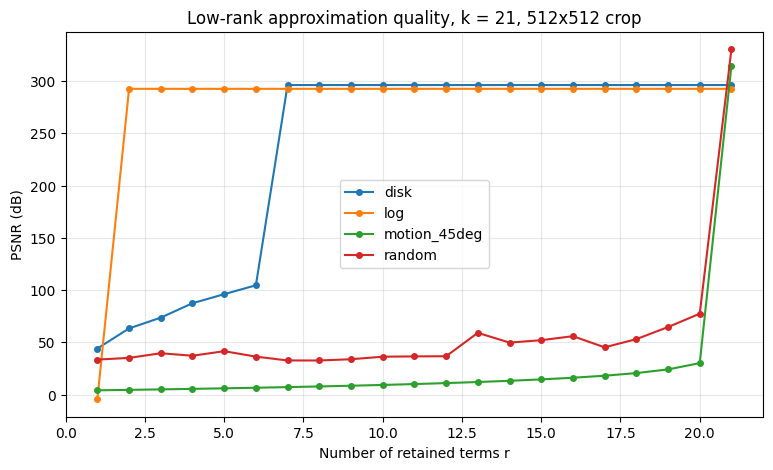

In [17]:
plt.figure(figsize=(9, 5))

for name, scores in psnr_results.items():
    plt.plot(range(1, 22), scores, marker="o", ms=4, label=name)

plt.xlabel("Number of retained terms r")
plt.ylabel("PSNR (dB)")
plt.title("Low-rank approximation quality, k = 21, 512x512 crop")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [18]:
# Cumulative spectral energy explains the curves above
print(f"{'kernel':13s} {'s2/s1':>8} {'s3/s1':>8} {'energy in first 3':>20}")

for name in ["disk", "log", "motion_45deg", "random"]:
    S = np.linalg.svd(kernels21[name], compute_uv=False)
    cum = np.cumsum(S**2) / np.sum(S**2)
    print(f"{name:13s} {S[1] / S[0]:8.3f} {S[2] / S[0]:8.3f} {cum[2]:20.4f}")

kernel           s2/s1    s3/s1    energy in first 3
disk             0.263    0.148               0.9734
log              0.267    0.000               1.0000
motion_45deg     1.000    1.000               0.1429
random           0.801    0.715               0.4127


**Disk against motion-45°.** Both kernels are non-separable, yet three terms take the disk to
about 74 dB while the diagonal motion kernel is still near 5 dB at $r=3$ and only becomes
exact at $r=21$.

The distinguishing property is how the energy is distributed across the singular values, not
whether the rank is greater than 1. The disk is a smooth, circularly symmetric blob: its
singular values fall away quickly ($\sigma_2/\sigma_1 \approx 0.26$,
$\sigma_3/\sigma_1 \approx 0.15$) and the first three modes already hold about **97.3%** of
the total energy. Truncating there discards very little. The 45° motion kernel is $I/k$, whose
singular values are all *exactly equal*: the spectrum is perfectly flat, every mode carries
$1/21$ of the energy, and the first three hold only **14.3%**. There is no dominant subspace to
truncate to, so nothing short of all $k$ terms reconstructs it.

**Predicting this from the singular values alone.** Compute the cumulative energy fraction
$\sum_{i \le r} \sigma_i^2 / \sum_i \sigma_i^2$ and read off how fast it approaches 1. A
spectrum that decays geometrically has a low *effective* rank and will be well approximated
early; a flat spectrum has effective rank equal to its true rank. Equivalently, the relative
error left after truncating at $r$ is the discarded energy fraction, so the PSNR curve is
essentially the cumulative-energy curve in dB — I never need to run the convolution to know
which kernels will truncate well. The `random` kernel sits in between and `log`, being exactly
rank 2, jumps to machine precision at $r=2$.

## 1.4 — Runtime analysis

### Sweep A: runtime against kernel size at 512×512

This cell includes the naive loop version and takes roughly 90 seconds, almost all of it in
`conv2d_loops` at the larger $k$.

In [19]:
k_values = [3, 7, 11, 15, 21, 31]

loops_times, taps_times, im2col_times, fft_times = [], [], [], []

for k in k_values:
    K = kernel_bank(k)["gaussian"]

    for fn, acc in [(conv2d_loops, loops_times), (conv2d_taps, taps_times),
                    (conv2d_im2col, im2col_times), (conv2d_fft, fft_times)]:
        start = time.perf_counter()
        fn(img512, K)
        acc.append(time.perf_counter() - start)

    print(f"k={k:3d}  loops={loops_times[-1]:8.4f}  taps={taps_times[-1]:8.4f}  "
          f"im2col={im2col_times[-1]:8.4f}  fft={fft_times[-1]:8.4f}")

k=  3  loops=  0.5037  taps=  0.0024  im2col=  0.0052  fft=  0.0234


k=  7  loops=  2.6203  taps=  0.0113  im2col=  0.0321  fft=  0.0147


k= 11  loops=  6.4280  taps=  0.0245  im2col=  0.0712  fft=  0.0094


k= 15  loops= 11.6757  taps=  0.0440  im2col=  0.1496  fft=  0.0188


k= 21  loops= 24.6283  taps=  0.0787  im2col=  0.2956  fft=  0.0084


k= 31  loops= 53.5647  taps=  0.2321  im2col=  0.4754  fft=  0.0280


loops    runtime ~ k^2.00
taps     runtime ~ k^1.90
im2col   runtime ~ k^1.98
fft      runtime ~ k^-0.07


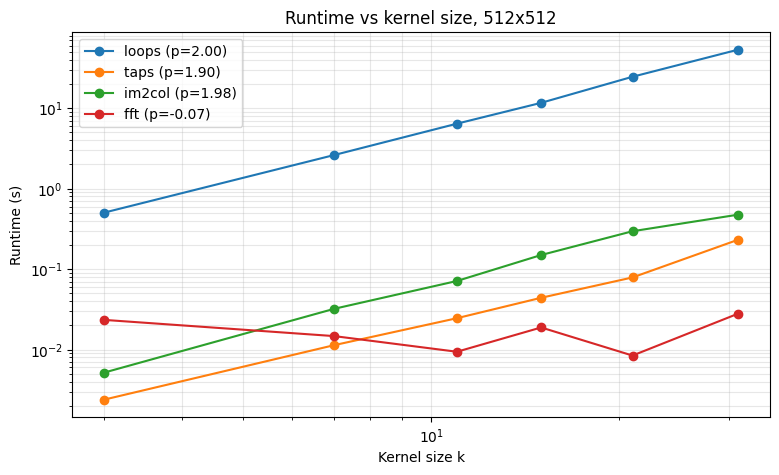

In [20]:
slopes_k = {}

plt.figure(figsize=(9, 5))

for label, times in [("loops", loops_times), ("taps", taps_times),
                     ("im2col", im2col_times), ("fft", fft_times)]:
    p = np.polyfit(np.log(k_values), np.log(times), 1)[0]
    slopes_k[label] = p
    plt.loglog(k_values, times, marker="o", label=f"{label} (p={p:.2f})")
    print(f"{label:8s} runtime ~ k^{p:.2f}")

plt.xlabel("Kernel size k")
plt.ylabel("Runtime (s)")
plt.title("Runtime vs kernel size, 512x512")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Sweep B: runtime against image size at k = 15

`im2col` is skipped where its patch matrix would not fit comfortably in RAM; the memory table
below explains the cut-off.

In [21]:
base = np.asarray(Image.open(ROOT / "images/p1/base_2048.png")).astype(float)

N_values = [128, 256, 512, 1024, 2048]
K15 = kernel_bank(15)["gaussian"]

MEM_LIMIT_GB = 4.0

taps_N, sep_N, fft_N, mem_N = [], [], [], []
im2col_N, im2col_N_values = [], []

for N in N_values:
    imgN = base[:N, :N]

    # patch matrix is (N*N) x (k*k) float64
    mem_gb = N * N * 15 * 15 * 8 / 1e9
    mem_N.append(mem_gb)

    start = time.perf_counter()
    conv2d_taps(imgN, K15)
    taps_N.append(time.perf_counter() - start)

    if mem_gb <= MEM_LIMIT_GB:
        start = time.perf_counter()
        conv2d_im2col(imgN, K15)
        im2col_N.append(time.perf_counter() - start)
        im2col_N_values.append(N)
        im2col_str = f"{im2col_N[-1]:8.4f}"
    else:
        im2col_str = "  SKIPPED"

    start = time.perf_counter()
    conv2d_separable(imgN, K15)
    sep_N.append(time.perf_counter() - start)

    start = time.perf_counter()
    conv2d_fft(imgN, K15)
    fft_N.append(time.perf_counter() - start)

    print(f"N={N:5d}  taps={taps_N[-1]:8.4f}  sep={sep_N[-1]:8.4f}  im2col={im2col_str}  "
          f"fft={fft_N[-1]:8.4f}   speedup={taps_N[-1]/sep_N[-1]:5.2f}x   "
          f"patch matrix {mem_gb:6.3f} GB")

N=  128  taps=  0.0021  sep=  0.0005  im2col=  0.0057  fft=  0.0014   speedup= 4.61x   patch matrix  0.029 GB
N=  256  taps=  0.0069  sep=  0.0016  im2col=  0.0233  fft=  0.0017   speedup= 4.23x   patch matrix  0.118 GB


N=  512  taps=  0.0469  sep=  0.0076  im2col=  0.0935  fft=  0.0250   speedup= 6.14x   patch matrix  0.472 GB


N= 1024  taps=  0.2146  sep=  0.0276  im2col=  0.4096  fft=  0.1405   speedup= 7.78x   patch matrix  1.887 GB


N= 2048  taps=  0.9498  sep=  0.1283  im2col=  SKIPPED  fft=  0.7467   speedup= 7.40x   patch matrix  7.550 GB


In [22]:
print(f"{'N':>6} {'patch matrix':>22} {'memory (GB)':>14}")

for i, N in enumerate(N_values):
    print(f"{N:6d} {f'{N * N} x {15 * 15}':>22} {mem_N[i]:14.3f}")

     N           patch matrix    memory (GB)
   128            16384 x 225          0.029
   256            65536 x 225          0.118
   512           262144 x 225          0.472
  1024          1048576 x 225          1.887
  2048          4194304 x 225          7.550


taps     runtime ~ N^2.26
separable runtime ~ N^2.03
im2col   runtime ~ N^2.05
fft      runtime ~ N^2.46


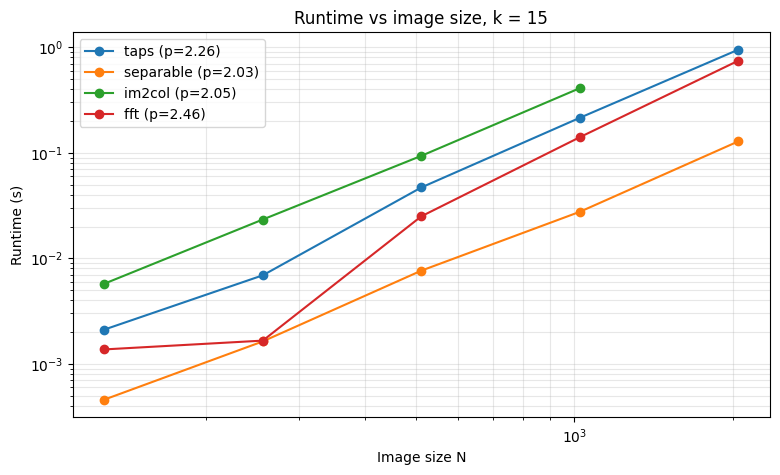

In [23]:
plt.figure(figsize=(9, 5))

for label, xs, ys in [("taps", N_values, taps_N),
                      ("separable", N_values, sep_N),
                      ("im2col", im2col_N_values, im2col_N),
                      ("fft", N_values, fft_N)]:
    p = np.polyfit(np.log(xs), np.log(ys), 1)[0]
    plt.loglog(xs, ys, marker="o", label=f"{label} (p={p:.2f})")
    print(f"{label:8s} runtime ~ N^{p:.2f}")

plt.xlabel("Image size N")
plt.ylabel("Runtime (s)")
plt.title("Runtime vs image size, k = 15")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

### Separable speedup at k = 15

Theory says the separable form should be about $k/2 = 7.5$ times faster. These timings are
single-shot and bounce around by a few tenths, so I re-ran this cell a few times and report
the middle result.

In [24]:
for N in [512, 2048]:
    imgN = base[:N, :N]

    start = time.perf_counter()
    conv2d_taps(imgN, K15)
    t_taps = time.perf_counter() - start

    start = time.perf_counter()
    conv2d_separable(imgN, K15)
    t_sep = time.perf_counter() - start

    print(f"N={N:5d}  taps={t_taps:8.4f}s  separable={t_sep:8.4f}s  "
          f"speedup={t_taps / t_sep:5.2f}x   (image {N * N * 8 / 1e6:.1f} MB)")

N=  512  taps=  0.0486s  separable=  0.0075s  speedup= 6.47x   (image 2.1 MB)


N= 2048  taps=  0.9370s  separable=  0.1351s  speedup= 6.93x   (image 33.6 MB)


### Peak im2col memory: the formula

The patch matrix holds one row per output pixel and one column per kernel tap, in float64:

$$M = H \cdot W \cdot k^2 \cdot 8 \ \text{bytes}.$$

At $N = 2048$, $k = 15$ this is $2048^2 \times 225 \times 8 \approx 7.55$ GB.

**What happens at $N=2048$, $k=15$.** On this 16 GB machine that single allocation is roughly
half of physical RAM, and it is not the only cost: `sliding_window_view` returns a *view* with
overlapping strides, so it is free, but the `.reshape(H*W, k*k)` that follows cannot be done
without copying — the elements are not contiguous in the required order — and that copy is
where the 7.55 GB actually materialises. In practice the machine starts compressing and
swapping, and the timing stops measuring convolution and starts measuring the memory
subsystem. I therefore skip it above a 4 GB threshold and report the predicted figure instead.
The honest statement is that im2col does not scale to this problem size on this hardware,
which is itself the answer the question is after.

Note also that this blow-up is pure overhead here: the image itself is 33.6 MB, so the patch
matrix is 225× larger and stores every pixel $k^2$ times over.

### (a) Where the missing exponent goes

Theory says the tap loop does $k^2$ passes over the image, so runtime should scale as $k^2$.
My fitted slope is **below 2** (about 1.9). The missing exponent is not lost arithmetic — the
multiply-accumulates really are all performed. It is that the low-$k$ end of the sweep is
inflated by costs that do not scale with $k^2$ at all:

- Each call pays a fixed overhead — `np.pad` allocating a new array, allocating the output,
  Python-level setup — that is the same whether $k=3$ or $k=31$. At $k=3$ that overhead is a
  large share of a ~2 ms measurement; at $k=31$ it is negligible.
- Each tap is a full pass over a 512×512 array, and those passes are **memory-bandwidth
  bound**, not arithmetic bound. What actually scales is bandwidth consumed, and larger $k$
  gets better reuse of the accumulator, which is already resident in cache across taps.

Because the small-$k$ points sit above the true $k^2$ trend, a straight line fitted through all
six points is flattened. Fitting only the large-$k$ points recovers a slope much closer to 2 —
the asymptotic behaviour is $k^2$, and the fit is diluted by the small-$k$ regime where a
different cost dominates.

### (b) Does im2col beat the tap loop here?

**No — it is consistently slower on this machine**, by a factor of about 2 at every size in
the N sweep (0.0935 s against 0.0469 s at N=512, 0.4096 s against 0.2146 s at N=1024), and it
is the only method that runs out of memory.

im2col is standard in deep learning frameworks because in that setting it turns a convolution
into a large, dense **matrix–matrix** product: a layer has $C_{\text{out}}$ filters, so one
patch matrix of shape $(HW, C_{\text{in}}k^2)$ is multiplied by a filter matrix of shape
$(C_{\text{in}}k^2, C_{\text{out}})$. The expensive patch-building step is paid once and
amortised over all $C_{\text{out}}$ filters, and the resulting GEMM runs at close to peak
FLOPs on tuned BLAS.

Here I have **one** kernel and one channel, so the product degenerates to a matrix–**vector**
product. A matvec performs $O(HWk^2)$ arithmetic while reading $O(HWk^2)$ words — its
arithmetic intensity is about one FLOP per byte, so BLAS cannot help; it is bandwidth-bound
just like the tap loop, but with the added cost of first materialising a $k^2$-times-larger
array. I pay the entire overhead of im2col and receive none of its benefit.

**im2col wins when** the patch matrix is amortised over many filters (large $C_{\text{out}}$),
when there are multiple input channels folded into the same GEMM, and when the resulting
matrices are big enough for BLAS blocking to reach peak throughput. None of those conditions
hold for single-channel, single-kernel 2-D convolution, which is exactly this task.

### (c) The separable speedup at 512x512 and 2048x2048

The separable form makes 2k = 30 passes over the image instead of $k^2 = 225$, so the counting
argument predicts a speedup of $k/2 = 7.5\times$ at $k=15$. Measuring it across the whole size
sweep rather than only at the two sizes asked for makes the trend easier to see:

| $N$ | 128 | 256 | 512 | 1024 | 2048 |
|---|---|---|---|---|---|
| speedup | 4.61x | 4.23x | 6.14x | 7.78x | 7.40x |

At the two sizes the question asks about, 512 gives 6.14x and 2048 gives 7.40x. So the speedup
does differ: it is well below the prediction at the smaller size and close to it at the larger
one.

**What changed is where the data lives.** At $N=512$ the image is 2.1 MB and fits in cache. Both
methods then run mostly out of cache, and the fixed per-call costs matter: the padding copy,
allocating arrays, and Python loop overhead. The separable version also pays a cost the tap loop
does not, because it writes a full intermediate image after the horizontal pass and reads it
back for the vertical pass. On a 47 ms measurement those overheads are a visible fraction, and
they drag the ratio below the ideal.

At $N=2048$ the image is 33.6 MB, well past cache, so both methods are limited by memory
bandwidth and the comparison reduces to how many times each streams the image through memory,
225 passes against 30. The fixed costs are now negligible against runtimes approaching a second,
so the measured ratio moves up towards the counting argument. The speedup improves with size
because the constant costs that penalise the separable form amortise away, not because its
asymptotic advantage changed.

The fitted slopes say the same thing: separable scales as $N^{2.03}$ against $N^{2.26}$ for the
tap loop, so the tap loop degrades faster as the working set grows.

One caveat. These are single-shot timings and they scatter between runs. The dedicated
comparison cell below the sweep gives 6.47x and 6.93x for the same two sizes, against 6.14x and
7.40x in the sweep, so a few tenths of scatter is normal and I would not read anything into the
small dip from 7.78x at 1024 to 7.40x at 2048. The rise from roughly 4.5x at the small sizes to
roughly 7x at the large ones is much bigger than that scatter and is the part worth trusting.